# Part A: Rebuild nine charts, then take them apart (36 marks)

For each case: **rebuild** the published chart from its recipe, check the self-check number, then write the **conclusion and decoy**, the **mechanism**, and plot the **redesign**.

Week 1-3 rules in force: `fig, ax = plt.subplots()`, no dual axes, title states the finding, `fig.savefig` before showing.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from vizlib import PALETTE, style_defaults, save_fig   # Week 3 toolkit
import tslib                                           # Week 4 toolkit

%matplotlib inline
style_defaults()

DATA = Path("data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def save(fig, name, note=None):
    """fig.savefig first (300 dpi, tight), THEN the figure is shown."""
    save_fig(fig, FIG / name, note)

def check(label, ok, detail=""):
    print(f"[{'PASS' if ok else 'FAIL'}] {label} {detail}")
C0, C1, C2 = PALETTE['series']
GREY = PALETTE['muted']

---
## Case 1: "Orders peak in Q1 and collapse every year"

**Recipe:** sort the 24 rows by the `month` column, line with markers, y from zero.

[PASS] 24 points 
[PASS] drops of 958 and 978 present 


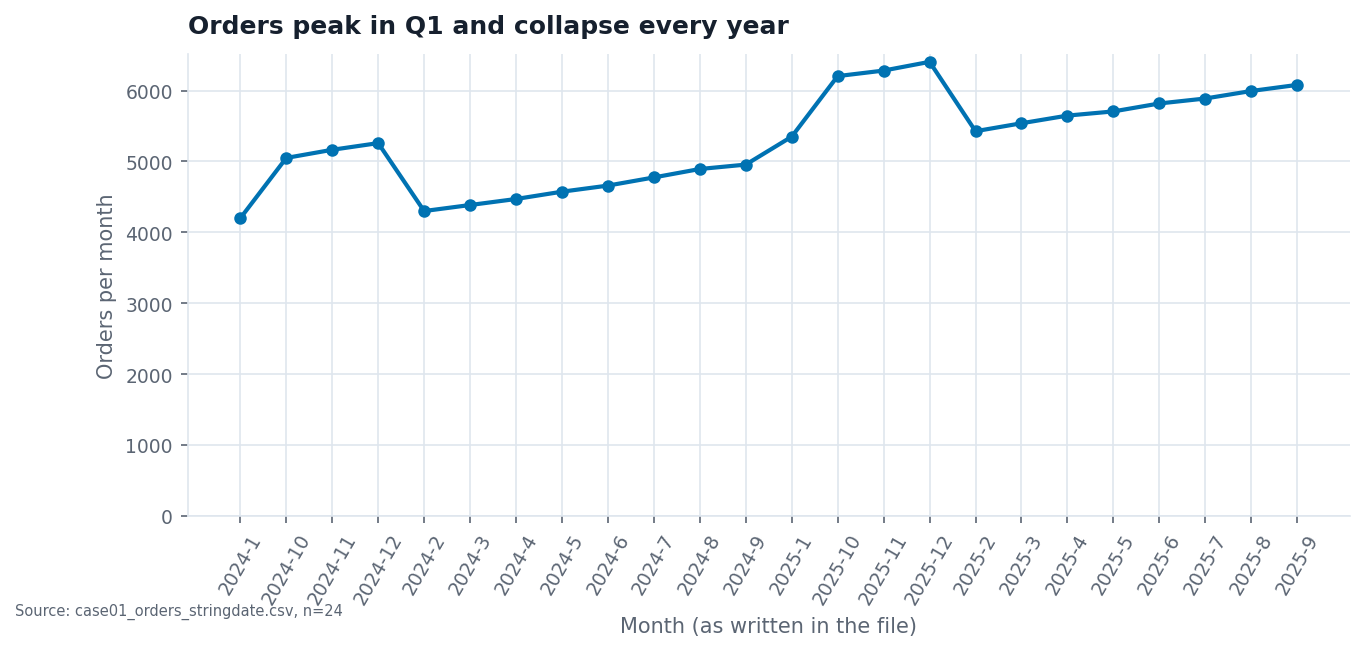

In [2]:
df = pd.read_csv(DATA / "case01_orders_stringdate.csv")
df = df.sort_values("month")                  # sorting the STRING column, as the recipe says
d = df.orders.diff().dropna().astype(int).tolist()
check("24 points", len(df) == 24)
check("drops of 958 and 978 present", -958 in d and -978 in d)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df.month, df.orders, marker="o", color=C0)
ax.set_ylim(0)
ax.set_title("Orders peak in Q1 and collapse every year")
ax.set_xlabel("Month (as written in the file)")
ax.set_ylabel("Orders per month")
ax.tick_params(axis="x", rotation=60)
save(fig, "case01_rebuild.png", "Source: case01_orders_stringdate.csv, n=24")
plt.show()

### Case 1: my analysis

- **Conclusion the chart invites (1 sentence):** Orders surge every autumn, collapse by about 1,000 in the new year, then climb again: a yearly cycle with a Q1 reset.
- **First objection I thought of, and the evidence it does not hold here:** "The dates are wrong" is not a finding, so test the usual alternative instead: that two branches or a mix change cause the drops. `branch` has one value (Gulberg) in all 24 rows, so no mix shift exists.
- **Mechanism (named precisely, with the number that shows it):** `month` is a **string** (`'2024-1'` … `'2025-12'`), so `sort_values` orders it as text and `'2024-10'`, `'2024-11'`, `'2024-12'` land before `'2024-2'`. The six two-digit months (Oct–Dec of both years) are the rows moved. The two "collapses" are just Dec→Feb jumps in that wrong order (5,250→4,292 = −958 and 6,400→5,422 = −978). After `pd.to_datetime`, **0 of 23** month-to-month changes are negative; the smallest is +59 and the mean is +96 a month. Year-on-year growth is +22% to +27% every month.

*Hint to myself:* check `df.month.dtype` and print `df.month.tolist()` after the sort.

negative month-to-month changes: 0 of 23; smallest +59; mean +96
year-on-year growth: +21.6% to +27.4%


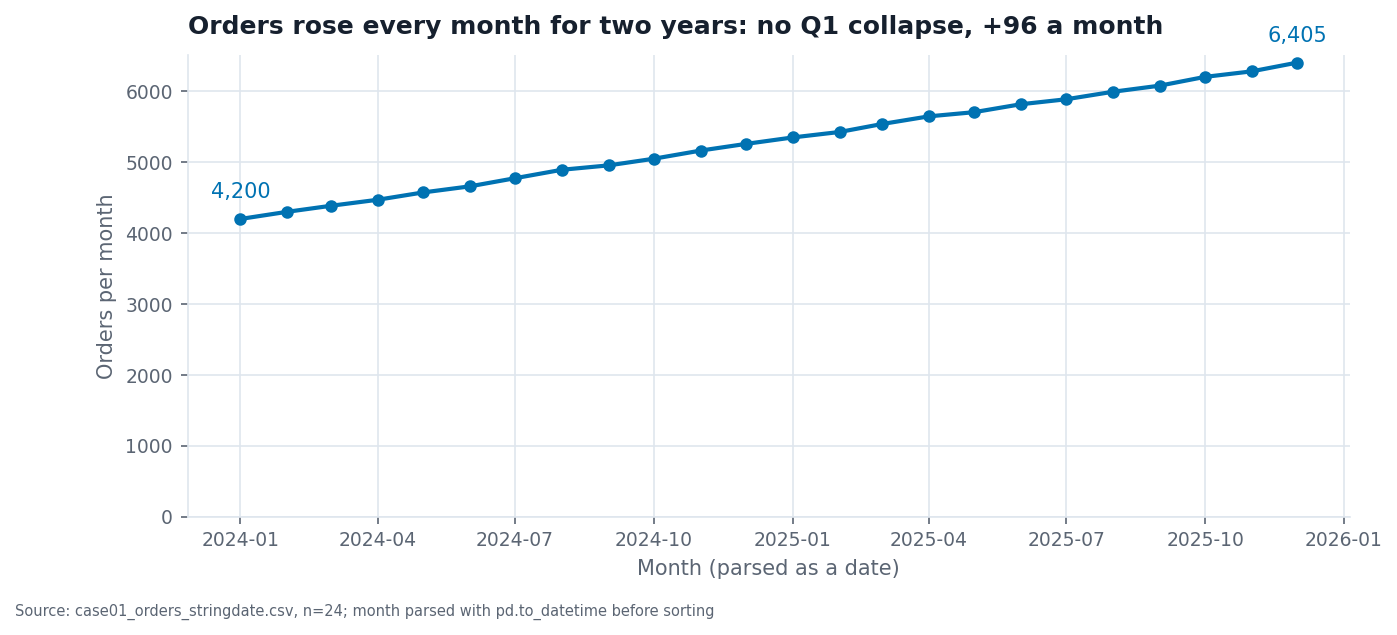

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# Redesign, case 1: parse the month as a date, then sort
df = pd.read_csv(DATA / "case01_orders_stringdate.csv")
df["dt"] = pd.to_datetime(df.month)
df = df.sort_values("dt")
ch = df.orders.diff().dropna()
print(f"negative month-to-month changes: {(ch < 0).sum()} of {len(ch)}; smallest {ch.min():+.0f}; mean {ch.mean():+.0f}")
yoy = df.orders.values[12:] / df.orders.values[:12] - 1
print(f"year-on-year growth: {yoy.min():+.1%} to {yoy.max():+.1%}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df.dt, df.orders, marker="o", color=C0)
ax.set_ylim(0)
ax.annotate("4,200", (df.dt.iloc[0], df.orders.iloc[0]), xytext=(0, 10), textcoords="offset points", ha="center", color=C0)
ax.annotate("6,405", (df.dt.iloc[-1], df.orders.iloc[-1]), xytext=(0, 10), textcoords="offset points", ha="center", color=C0)
ax.set_title("Orders rose every month for two years: no Q1 collapse, +96 a month")
ax.set_xlabel("Month (parsed as a date)")
ax.set_ylabel("Orders per month")
save(fig, "case01_redesign.png", "Source: case01_orders_stringdate.csv, n=24; month parsed with pd.to_datetime before sorting")
plt.show()

---
## Case 2: "Sales grew steadily, 22%, across the quarter"

**Recipe:** plot `sales_pkr_k` against the row number, add a least-squares trend line.

[PASS] 69 points, 207 -> 253, +22% (n=69, 207->253, +22.2%)


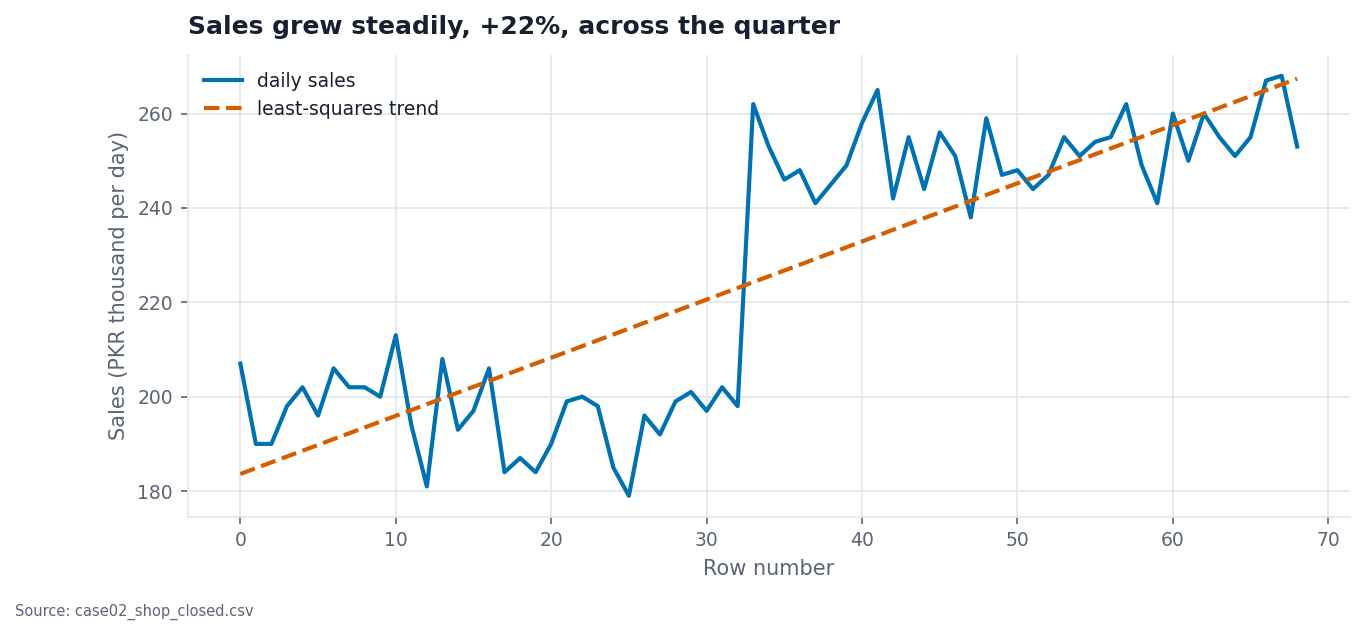

In [4]:
df = pd.read_csv(DATA / "case02_shop_closed.csv")
x, y = np.arange(len(df)), df.sales_pkr_k.to_numpy()
rise = (y[-1] / y[0] - 1) * 100
check("69 points, 207 -> 253, +22%", len(df) == 69 and y[0] == 207 and y[-1] == 253 and round(rise) == 22,
      f"(n={len(df)}, {y[0]}->{y[-1]}, {rise:+.1f}%)")
m, b = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, y, color=C0, label="daily sales")
ax.plot(x, m * x + b, color=C1, linestyle="--", label="least-squares trend")
ax.set_title("Sales grew steadily, +22%, across the quarter")
ax.set_xlabel("Row number")
ax.set_ylabel("Sales (PKR thousand per day)")
ax.legend()
save(fig, "case02_rebuild.png", "Source: case02_shop_closed.csv")
plt.show()

### Case 2: my analysis

- **Conclusion the chart invites (1 sentence):** Sales grew steadily, about 22%, across the quarter.
- **First objection I thought of, and the evidence it does not hold here:** Maybe 207→253 is just two noisy days at the ends. It is not: the mean of the 33 days before the break is 196.2 and of the 36 days after is 252.3 (+28.6%), larger than the endpoint rise, so the endpoints understate it.
- **Mechanism (named precisely, with the number that shows it):** The shop was **closed 3–23 Feb (21 days)**: the file has 69 rows for 90 calendar days. Plotting against row number deletes the gap, so a one-time level shift at reopening (197 → 262 on 24 Feb) looks like a ramp, and the trend line is fitted through a step. Inside each open spell sales are flat: slope −0.16 per day before, +0.23 per day after, with SD about 8 around each level.

*Hint to myself:* compare `len(df)` with the number of days between the first and last date.

69 rows over 90 calendar days; closed 2025-02-03 to 2025-02-23 (21 days)
mean before 196.2, after 252.3: +28.6%


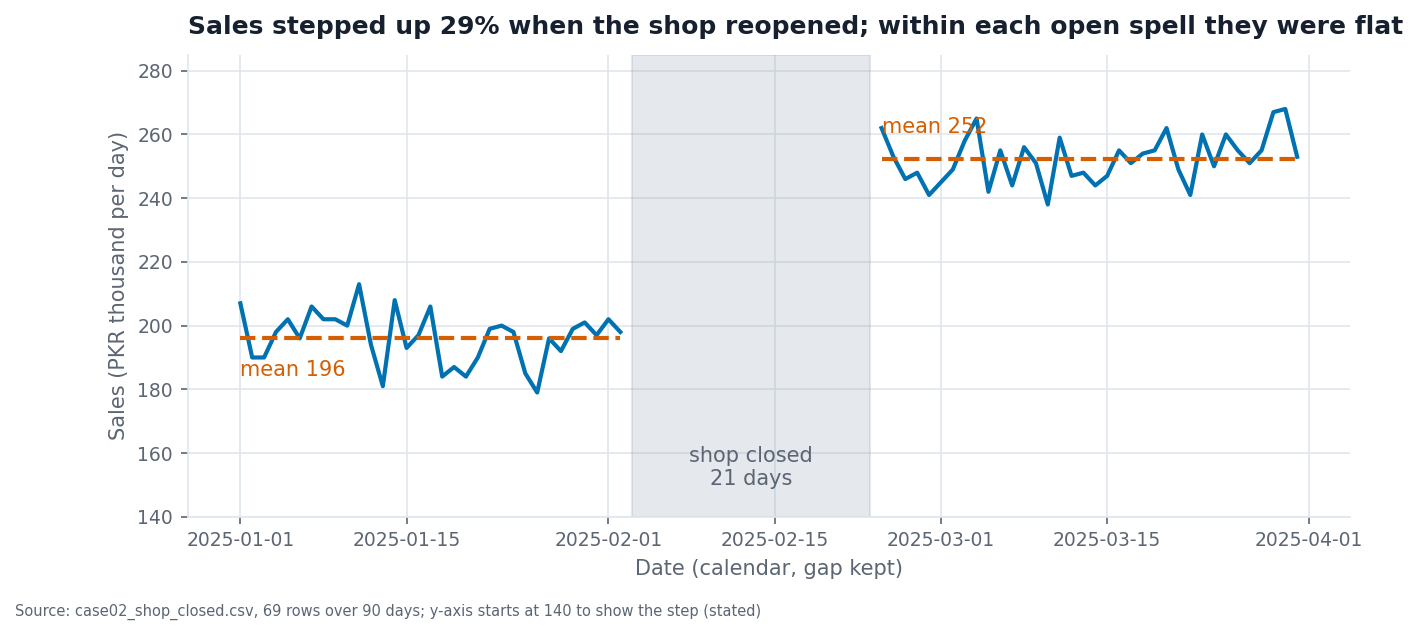

In [5]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# Redesign, case 2: put the calendar back, break the line at the closure
df = pd.read_csv(DATA / "case02_shop_closed.csv", parse_dates=["date"]).set_index("date")
full = tslib.reindex_full(df.sales_pkr_k, "D")
gap = full[full.isna()].index
pre, post = df[df.index < gap.min()].sales_pkr_k, df[df.index > gap.max()].sales_pkr_k
print(f"{len(df)} rows over {len(full)} calendar days; closed {gap.min().date()} to {gap.max().date()} ({len(gap)} days)")
print(f"mean before {pre.mean():.1f}, after {post.mean():.1f}: {post.mean()/pre.mean()-1:+.1%}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(gap.min(), gap.max(), color=GREY, alpha=0.25)
ax.text(gap.min() + (gap.max() - gap.min()) / 2, 150, "shop closed\n21 days", ha="center", color=PALETTE["ink_soft"])
ax.plot(full.index, full.values, color=C0)
ax.hlines(pre.mean(), pre.index.min(), pre.index.max(), color=C1, linestyle="--")
ax.hlines(post.mean(), post.index.min(), post.index.max(), color=C1, linestyle="--")
ax.text(pre.index.min(), pre.mean() - 12, f"mean {pre.mean():.0f}", color=C1)
ax.text(post.index.min(), post.mean() + 8, f"mean {post.mean():.0f}", color=C1)
ax.set_ylim(140, 285)
ax.set_title("Sales stepped up 29% when the shop reopened; within each open spell they were flat")
ax.set_xlabel("Date (calendar, gap kept)")
ax.set_ylabel("Sales (PKR thousand per day)")
save(fig, "case02_redesign.png", "Source: case02_shop_closed.csv, 69 rows over 90 days; y-axis starts at 140 to show the step (stated)")
plt.show()

---
## Case 3: "Peak load jumped 43% overnight on 1 July"

**Recipe:** resample `concurrent_users` to daily with `.sum()`, line, y from zero.

[PASS] June ~8,800, July ~12,500, +43% (June 8,782, July 12,543, +43%)


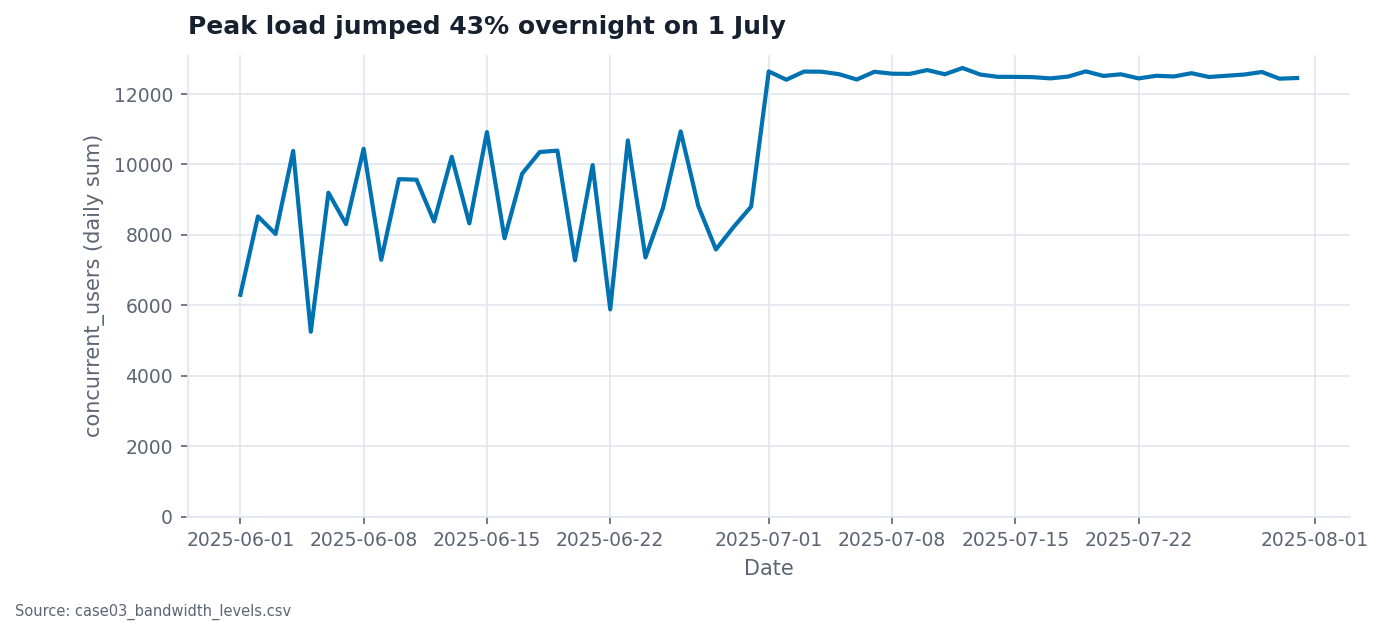

In [6]:
df = pd.read_csv(DATA / "case03_bandwidth_levels.csv", parse_dates=["ts"])
daily = df.set_index("ts").concurrent_users.resample("D").sum()
jun, jul = daily[daily.index.month == 6].mean(), daily[daily.index.month == 7].mean()
check("June ~8,800, July ~12,500, +43%", abs(jun - 8800) < 100 and abs(jul - 12500) < 100,
      f"(June {jun:,.0f}, July {jul:,.0f}, {(jul/jun-1)*100:+.0f}%)")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily.values, color=C0)
ax.set_ylim(0)
ax.set_title("Peak load jumped 43% overnight on 1 July")
ax.set_xlabel("Date")
ax.set_ylabel("concurrent_users (daily sum)")
save(fig, "case03_rebuild.png", "Source: case03_bandwidth_levels.csv")
plt.show()

### Case 3: my analysis

- **Conclusion the chart invites (1 sentence):** Peak load jumped 43% overnight on 1 July.
- **First objection I thought of, and the evidence it does not hold here:** Perhaps there really was a July traffic event. The hourly rows say no: the mean of `concurrent_users` per recorded hour is 534 in June and 523 in July (−2%), and the hours either side of midnight on 30 Jun/1 Jul are ordinary (705, 648, 391, 406, 423).
- **Mechanism (named precisely, with the number that shows it):** `concurrent_users` is a **level** (a count at an instant), and `.sum()` adds levels as if they were a flow, so a daily sum measures *how many hourly rows were recorded*. June has **493 of 720 hours** (about 16.4 rows a day, with 5–20 missing most days); July has **744 of 744** (24 a day). 24/16.4 = 1.46, times the −2% level change = 1.43, which is the "+43%". The honest daily aggregate is the mean (June 536, July 523).

*Hint to myself:* is concurrent_users a level or a flow? How many hourly rows does each day actually have?

June: hours recorded 493 of 720; mean per hour 534
July: hours recorded 744 of 744; mean per hour 523


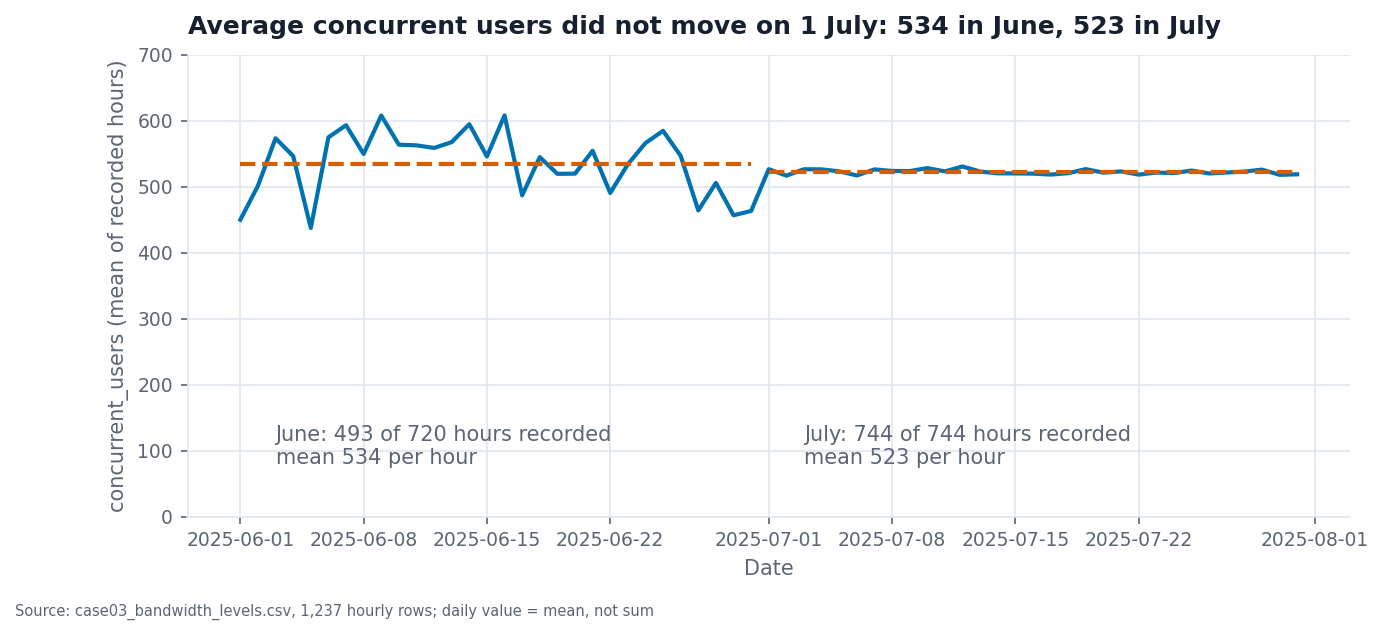

In [7]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# Redesign, case 3: a level is averaged, never summed
df = pd.read_csv(DATA / "case03_bandwidth_levels.csv", parse_dates=["ts"]).set_index("ts")
x = df.concurrent_users
daily_mean = x.resample("D").mean()
rows = x.resample("D").count()
for m, nm in [(6, "June"), (7, "July")]:
    print(f"{nm}: hours recorded {rows[rows.index.month == m].sum()} of {rows[rows.index.month == m].size * 24}; "
          f"mean per hour {x[x.index.month == m].mean():.0f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily_mean.index, daily_mean.values, color=C0)
ax.hlines(x[x.index.month == 6].mean(), pd.Timestamp("2025-06-01"), pd.Timestamp("2025-06-30"), color=C1, linestyle="--")
ax.hlines(x[x.index.month == 7].mean(), pd.Timestamp("2025-07-01"), pd.Timestamp("2025-07-31"), color=C1, linestyle="--")
ax.text(pd.Timestamp("2025-06-03"), 80, "June: 493 of 720 hours recorded\nmean 534 per hour", color=PALETTE["ink_soft"])
ax.text(pd.Timestamp("2025-07-03"), 80, "July: 744 of 744 hours recorded\nmean 523 per hour", color=PALETTE["ink_soft"])
ax.set_ylim(0, 700)
ax.set_title("Average concurrent users did not move on 1 July: 534 in June, 523 in July")
ax.set_xlabel("Date")
ax.set_ylabel("concurrent_users (mean of recorded hours)")
save(fig, "case03_redesign.png", "Source: case03_bandwidth_levels.csv, 1,237 hourly rows; daily value = mean, not sum")
plt.show()

---
## Case 4: "The new checkout flow started working on 7 September"

**Recipe:** raw conversion in grey, 31-day trailing rolling mean on top, mark the turning point.

[PASS] trailing mean bottoms on 2025-09-07 (2025-09-07)


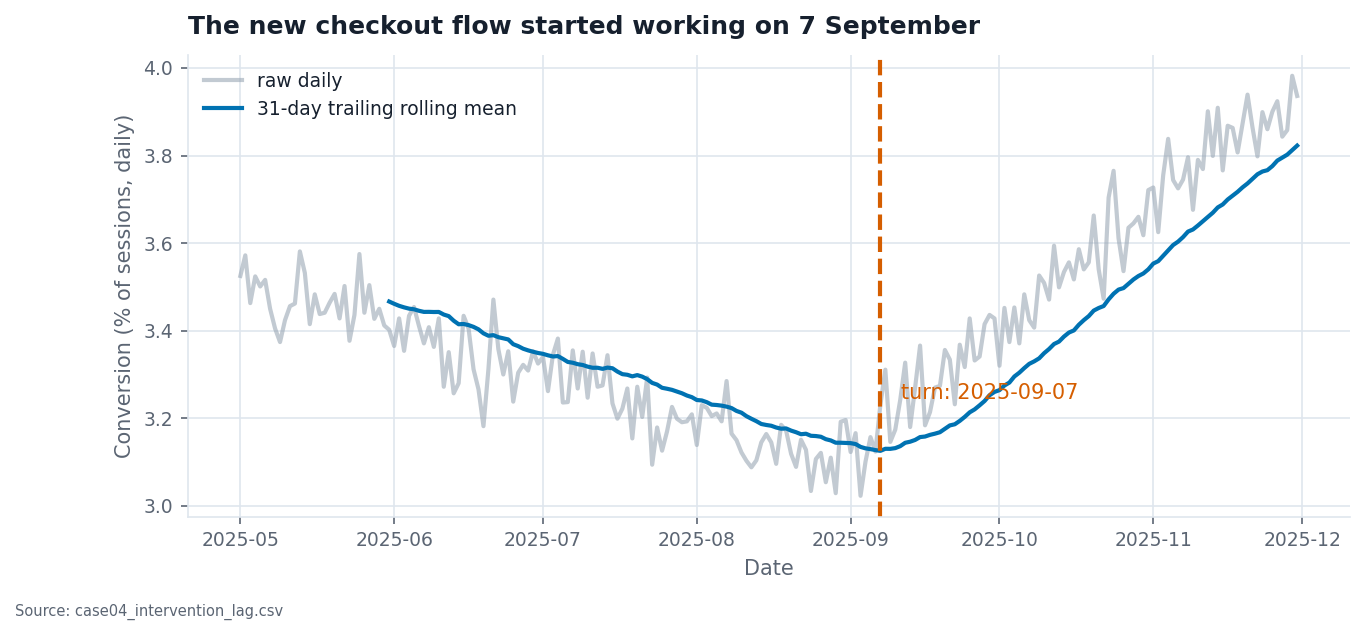

In [8]:
df = pd.read_csv(DATA / "case04_intervention_lag.csv", parse_dates=["date"]).set_index("date")
tm = df.conversion_pct.rolling(31).mean()
turn = tm.idxmin()
check("trailing mean bottoms on 2025-09-07", str(turn.date()) == "2025-09-07", f"({turn.date()})")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df.index, df.conversion_pct, color=GREY, alpha=0.6, label="raw daily")
ax.plot(tm.index, tm.values, color=C0, label="31-day trailing rolling mean")
ax.axvline(turn, color=C1, linestyle="--")
ax.annotate(f"turn: {turn.date()}", (turn, tm.min()), xytext=(10, 25), textcoords="offset points", color=C1)
ax.set_title("The new checkout flow started working on 7 September")
ax.set_xlabel("Date")
ax.set_ylabel("Conversion (% of sessions, daily)")
ax.legend()
save(fig, "case04_rebuild.png", "Source: case04_intervention_lag.csv")
plt.show()

### Case 4: my analysis

- **Conclusion the chart invites (1 sentence):** The new checkout flow started working on 7 September.
- **First objection I thought of, and the evidence it does not hold here:** That the dip is just noise: the 7-day mean falls steadily 3.46% → 3.12% from May to 4 Sep, then climbs to 3.87% by late Nov, so the V shape is far larger than the daily scatter (a few hundredths).
- **Mechanism (named precisely, with the number that shows it):** A trailing window reports the mean of the **31 days that end at t**, so it can only see a turn after the window has filled. The trailing minimum is 2025-09-07; the centred minimum of the same window is **2025-08-23**, a gap of **15 days = the half-window (31//2)**. A piecewise-linear fit to the raw data puts the breakpoint at 2025-08-28. The turn is therefore no later than late August, and the data contains no launch date, so it cannot say what caused it.

*Hint to myself:* use `tslib.lag_at_turn(..., 31)` and compare trailing vs centred.

trailing turn 2025-09-07, centred turn 2025-08-23, lag 15 days, half-window 15


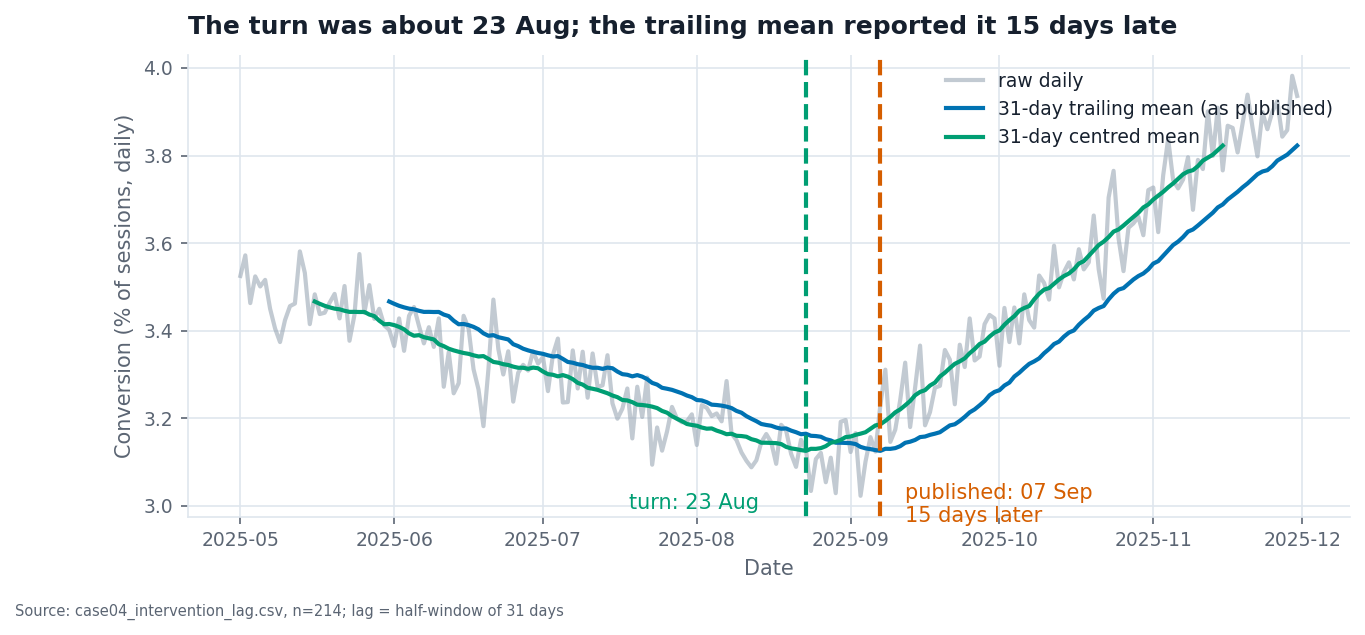

In [9]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# Redesign, case 4: centred window for locating a turn, with the lag shown
df = pd.read_csv(DATA / "case04_intervention_lag.csv", parse_dates=["date"]).set_index("date")
lg = tslib.lag_at_turn(df.conversion_pct, 31, how="min")
trail = df.conversion_pct.rolling(31).mean()
cent = df.conversion_pct.rolling(31, center=True).mean()
print(f"trailing turn {lg['trailing_turn'].date()}, centred turn {lg['centred_turn'].date()}, "
      f"lag {lg['lag_periods']} days, half-window {lg['half_window']}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df.index, df.conversion_pct, color=GREY, alpha=0.6, label="raw daily")
ax.plot(trail.index, trail.values, color=C0, label="31-day trailing mean (as published)")
ax.plot(cent.index, cent.values, color=PALETTE["series"][2], label="31-day centred mean")
ax.axvline(lg["centred_turn"], color=PALETTE["series"][2], linestyle="--")
ax.axvline(lg["trailing_turn"], color=C1, linestyle="--")
ax.annotate(f"turn: {lg['centred_turn']:%d %b}", (lg["centred_turn"], cent.min()), xytext=(-85, -28),
            textcoords="offset points", color=PALETTE["series"][2])
ax.annotate(f"published: {lg['trailing_turn']:%d %b}\n{lg['lag_periods']} days later", (lg["trailing_turn"], trail.min()),
            xytext=(12, -34), textcoords="offset points", color=C1)
ax.set_title("The turn was about 23 Aug; the trailing mean reported it 15 days late")
ax.set_xlabel("Date")
ax.set_ylabel("Conversion (% of sessions, daily)")
ax.legend(loc="upper right")
save(fig, "case04_redesign.png", "Source: case04_intervention_lag.csv, n=214; lag = half-window of 31 days")
plt.show()

---
## Case 5: "Revenue has fallen for six straight months"

**Recipe:** May to November 2025 only, line with markers, y from zero.

[PASS] 7 points, 158.8 -> 92.2, -41.9% (n=7, -41.9%)


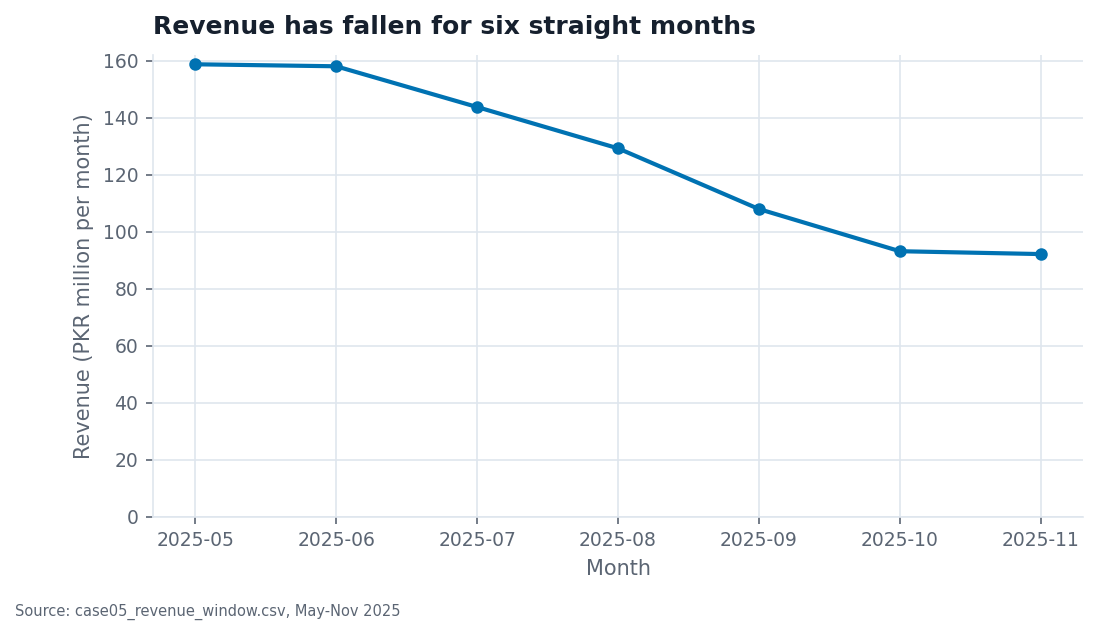

In [10]:
df = pd.read_csv(DATA / "case05_revenue_window.csv")
w = df[(df.month >= "2025-05") & (df.month <= "2025-11")]
first, last = w.revenue_pkr_m.iloc[0], w.revenue_pkr_m.iloc[-1]
fall = (last / first - 1) * 100
check("7 points, 158.8 -> 92.2, -41.9%", len(w) == 7 and first == 158.8 and last == 92.2 and round(fall, 1) == -41.9,
      f"(n={len(w)}, {fall:+.1f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(w.month, w.revenue_pkr_m, marker="o", color=C0)
ax.set_ylim(0)
ax.set_title("Revenue has fallen for six straight months")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (PKR million per month)")
save(fig, "case05_rebuild.png", "Source: case05_revenue_window.csv, May-Nov 2025")
plt.show()

### Case 5: my analysis

- **Conclusion the chart invites (1 sentence):** Revenue has fallen for six straight months, so the business is in decline.
- **First objection I thought of, and the evidence it does not hold here:** The two objections already excluded: the axis starts at zero and n=7 is not the issue. The remaining one is "it really is falling": year on year it is not. November 2025 (92.2) is 9.2% above November 2024 (84.4).
- **Mechanism (named precisely, with the number that shows it):** **Window selection on a seasonal series.** The 7 rows start at the annual peak (May) and end at the annual trough (Nov), and the file holds 36 months. The same May→Nov fall is −42.4% in 2023 and −42.8% in 2024, versus −41.9% in 2025. Calendar-year revenue is 1,254.7 → 1,361.9 → 1,496.3 (+8.5%, then +9.9%).

*Hint to myself:* the axis is NOT truncated and n is NOT too small. Look at what the file holds beyond these 7 rows.

2023 May->Nov -42.4%, year total 1,254.7
2024 May->Nov -42.8%, year total 1,361.9
2025 May->Nov -41.9%, year total 1,496.3


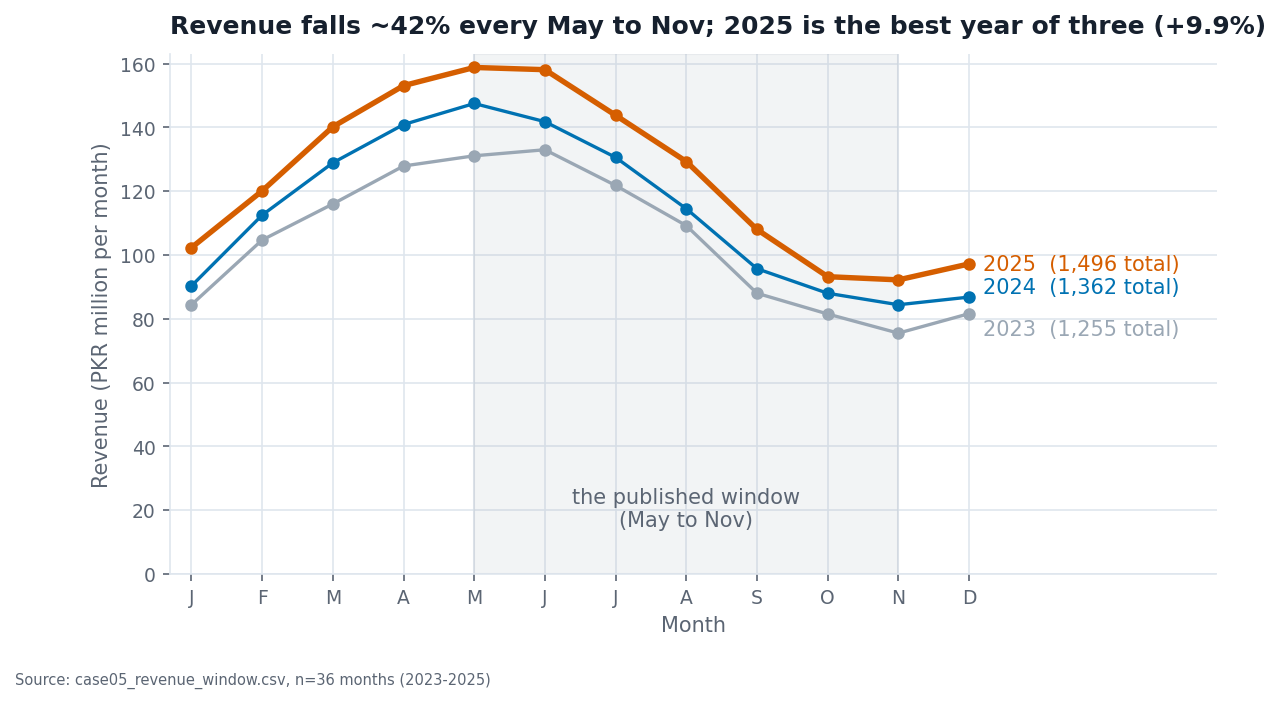

In [11]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# Redesign, case 5: all 36 months, one line per year on the same calendar
df = pd.read_csv(DATA / "case05_revenue_window.csv")
df["y"], df["m"] = df.month.str[:4], df.month.str[5:].astype(int)
piv = df.pivot(index="m", columns="y", values="revenue_pkr_m")
for y in piv: print(y, f"May->Nov {piv.loc[11, y] / piv.loc[5, y] - 1:+.1%}, year total {piv[y].sum():,.1f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
cols = {"2023": GREY, "2024": C0, "2025": C1}
for y in piv:
    ax.plot(piv.index, piv[y], marker="o", color=cols[y], linewidth=2.6 if y == "2025" else 1.6)
    ax.text(12.2, piv.loc[12, y] + {"2023": -5, "2024": 3}.get(y, 0), f"{y}  ({piv[y].sum():,.0f} total)", color=cols[y], va="center")
ax.axvspan(5, 11, color=GREY, alpha=0.12)
ax.text(8, 15, "the published window\n(May to Nov)", ha="center", color=PALETTE["ink_soft"])
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("JFMAMJJASOND"))
ax.set_xlim(0.7, 15.5); ax.set_ylim(0)
ax.set_title("Revenue falls ~42% every May to Nov; 2025 is the best year of three (+9.9%)")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (PKR million per month)")
save(fig, "case05_redesign.png", "Source: case05_revenue_window.csv, n=36 months (2023-2025)")
plt.show()

---
## Case 6: "Orders collapsed in October"

**Recipe:** resample orders to monthly totals with `.sum()`, bars from zero.

[PASS] ten bars; Sep 10,805; Oct 4,041 (37%) (Oct/Sep = 37%)


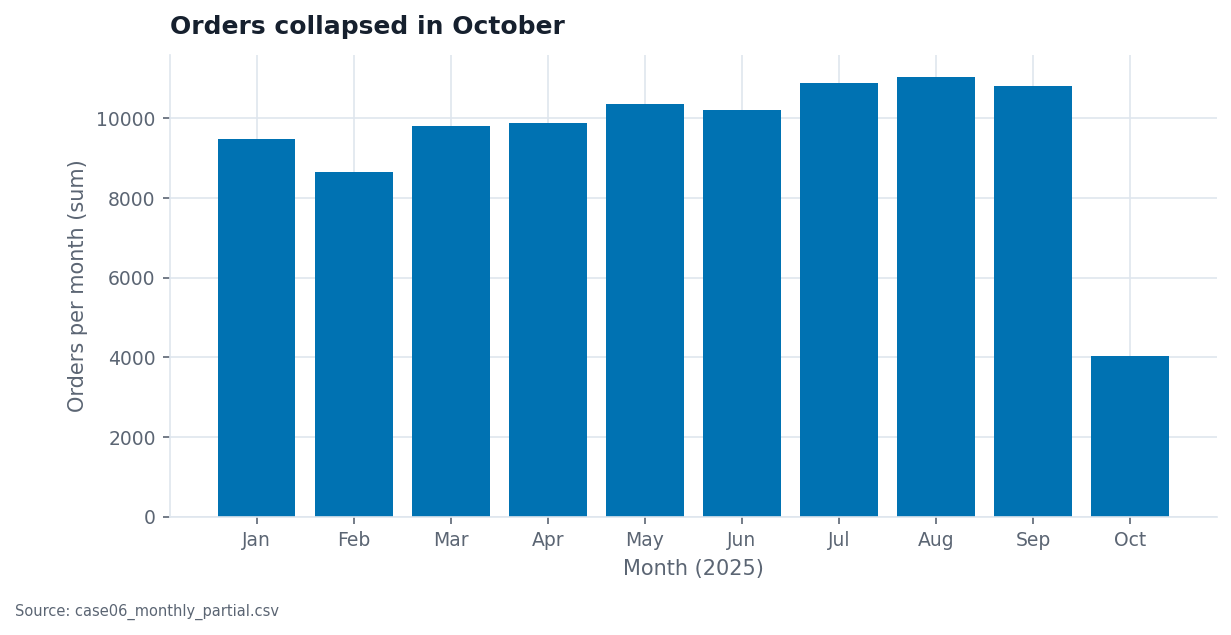

In [12]:
df = pd.read_csv(DATA / "case06_monthly_partial.csv", parse_dates=["date"]).set_index("date")
m = df.orders.resample("MS").sum()
check("ten bars; Sep 10,805; Oct 4,041 (37%)", len(m) == 10 and m.iloc[-2] == 10805 and m.iloc[-1] == 4041,
      f"(Oct/Sep = {m.iloc[-1]/m.iloc[-2]:.0%})")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(m.index.strftime("%b"), m.values, color=C0)
ax.set_title("Orders collapsed in October")
ax.set_xlabel("Month (2025)")
ax.set_ylabel("Orders per month (sum)")
save(fig, "case06_rebuild.png", "Source: case06_monthly_partial.csv")
plt.show()

### Case 6: my analysis

- **Conclusion the chart invites (1 sentence):** Orders collapsed in October, to 37% of September.
- **First objection I thought of, and the evidence it does not hold here:** A real demand shock such as an outage or a competitor would show up in the days we have. It does not: the 11 October days average 367 orders a day versus 360 in September (+2%).
- **Mechanism (named precisely, with the number that shows it):** **Partial period summed against full ones.** The file ends on 2025-10-11, so the October bar adds **11 days (4,041)** against 30 days for September (10,805). 11/30 = 0.37, which is exactly the "37%". Every other month has all its days (28–31 rows).

*Hint to myself:* how many days of October are in the file? What is the last date?

             mean  count
date                    
2025-01-01  305.9     31
2025-02-01  309.2     28
2025-03-01  316.7     31
2025-04-01  329.5     30
2025-05-01  333.8     31
2025-06-01  339.9     30
2025-07-01  351.1     31
2025-08-01  356.2     31
2025-09-01  360.2     30
2025-10-01  367.4     11
Oct vs Sep per-day: +2.0%


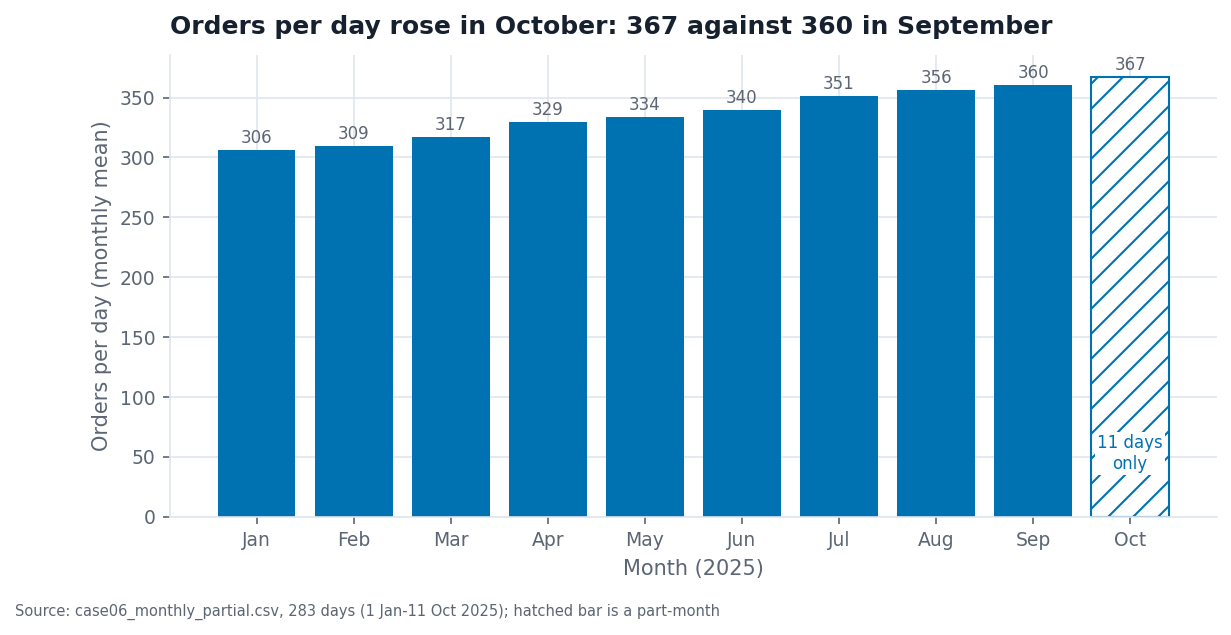

In [13]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# Redesign, case 6: a rate per day, with the partial month flagged
df = pd.read_csv(DATA / "case06_monthly_partial.csv", parse_dates=["date"]).set_index("date")
g = df.orders.resample("MS").agg(["mean", "count"])
print(g.round(1).to_string())
print(f"Oct vs Sep per-day: {g['mean'].iloc[-1] / g['mean'].iloc[-2] - 1:+.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(g.index.strftime("%b"), g["mean"], color=C0)
bars[-1].set_hatch("//"); bars[-1].set_facecolor("white"); bars[-1].set_edgecolor(C0)
for b, (_, r) in zip(bars, g.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, r["mean"] + 6, f"{r['mean']:.0f}", ha="center", color=PALETTE["ink_soft"], fontsize=8)
ax.text(bars[-1].get_x() + bars[-1].get_width() / 2, 40, "11 days\nonly", ha="center", color=C0, fontsize=8, bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_title("Orders per day rose in October: 367 against 360 in September")
ax.set_xlabel("Month (2025)")
ax.set_ylabel("Orders per day (monthly mean)")
save(fig, "case06_redesign.png", "Source: case06_monthly_partial.csv, 283 days (1 Jan-11 Oct 2025); hatched bar is a part-month")
plt.show()

---
## Case 7: "Product D has been erratic since mid-2024"

**Recipe:** stacked area of the four products in column order, product_a at the bottom.

[PASS] envelope ~548 to ~709 (548.3 to 708.7)


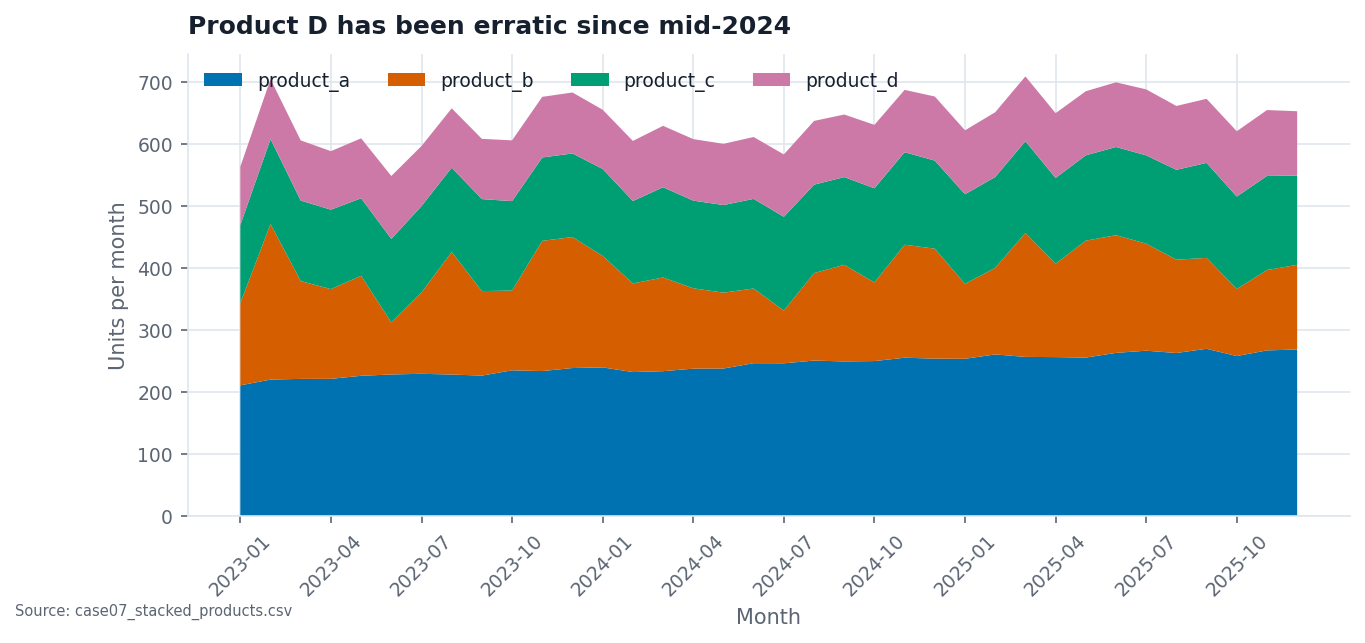

In [14]:
df = pd.read_csv(DATA / "case07_stacked_products.csv")
cols = ["product_a", "product_b", "product_c", "product_d"]
tot = df[cols].sum(axis=1)
check("envelope ~548 to ~709", round(tot.min()) == 548 and round(tot.max()) == 709, f"({tot.min():.1f} to {tot.max():.1f})")

fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(df.month, [df[c] for c in cols], labels=cols, colors=PALETTE["series"] + [PALETTE["series_4th"]])
ax.set_title("Product D has been erratic since mid-2024")
ax.set_xlabel("Month")
ax.set_ylabel("Units per month")
ax.set_xticks(range(0, len(df), 3))
ax.set_xticklabels(df.month.iloc[::3], rotation=45)
ax.legend(loc="upper left", ncol=4)
save(fig, "case07_rebuild.png", "Source: case07_stacked_products.csv")
plt.show()

### Case 7: my analysis

- **Conclusion the chart invites (1 sentence):** Product D has been erratic since mid-2024.
- **First objection I thought of, and the evidence it does not hold here:** That D is simply volatile. Its own series is the calmest of the four: SD 3.6 units (3.5% of its mean), mean absolute month-to-month change 1.6, and this is no different after mid-2024 (SD 1.7) than before (SD 1.9).
- **Mechanism (named precisely, with the number that shows it):** **Stacking draws each layer's wobble on top of everything beneath it.** D is the top layer, so its upper edge is a+b+c+d and it inherits every swing underneath. The swing is **product_b** (SD 35.6, mean absolute change 34.8 a month; 250.6 in Feb 2023, 83.9 in Jun 2023, 84.8 in Jul 2024), the column the recipe never isolates. A's SD is 16.0, C's 7.3.

*Hint to myself:* in a stack, whose wobble is drawn on top of whose? Plot each product on its own baseline.

{'product_a': 16.0, 'product_b': 35.6, 'product_c': 7.3, 'product_d': 3.6}
{'product_a': 3.7, 'product_b': 34.8, 'product_c': 5.2, 'product_d': 1.6}


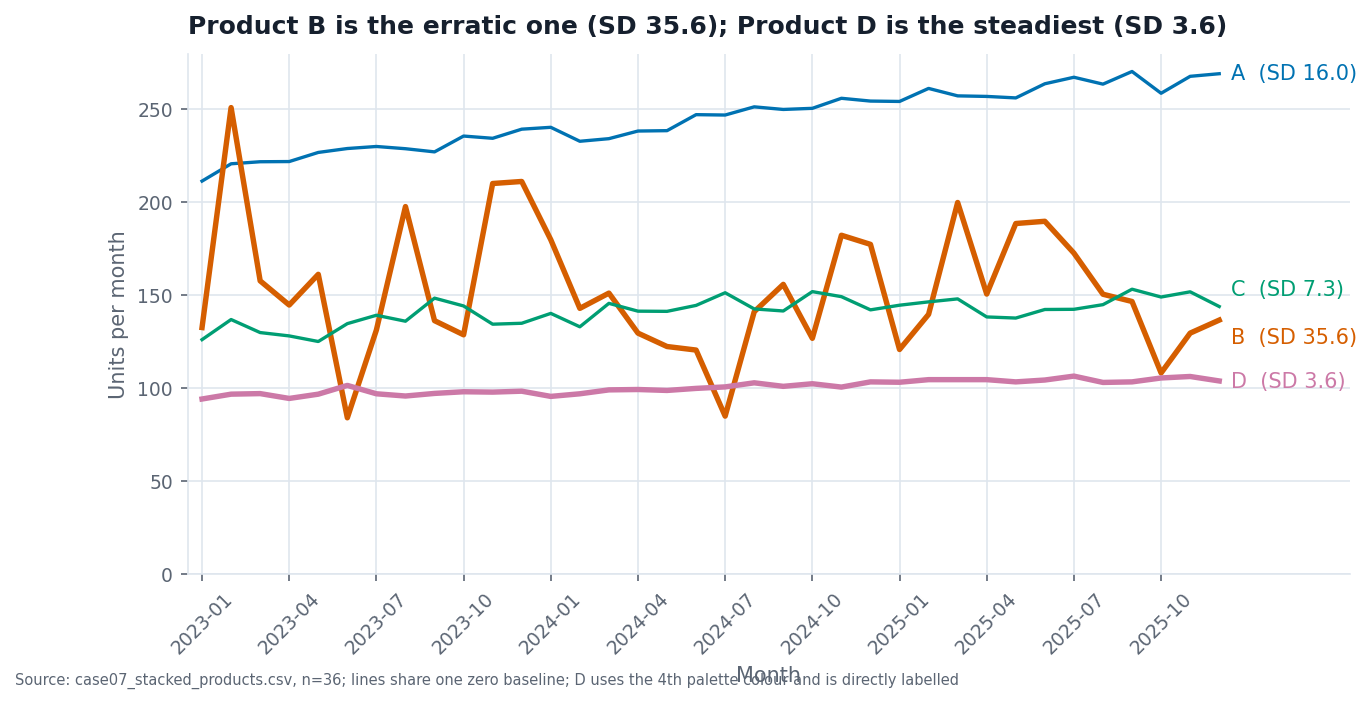

In [15]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# Redesign, case 7: each product on its own baseline (no stacking)
df = pd.read_csv(DATA / "case07_stacked_products.csv")
cols = ["product_a", "product_b", "product_c", "product_d"]
colours = dict(zip(cols, PALETTE["series"] + [PALETTE["series_4th"]]))
print(df[cols].std().round(1).to_dict())
print((df[cols].diff().abs().mean()).round(1).to_dict())

fig, ax = plt.subplots(figsize=(10, 4.5))
for c in cols:
    ax.plot(df.month, df[c], color=colours[c], linewidth=2.6 if c in ("product_b", "product_d") else 1.6)
    ax.text(len(df) - 0.6, df[c].iloc[-1] + {"product_c": 9, "product_b": -9}.get(c, 0), f"{c[-1].upper()}  (SD {df[c].std():.1f})", color=colours[c], va="center")
ax.set_ylim(0); ax.set_xlim(-0.5, len(df) + 3.5)
ax.set_xticks(range(0, len(df), 3)); ax.set_xticklabels(df.month.iloc[::3], rotation=45)
ax.set_title("Product B is the erratic one (SD 35.6); Product D is the steadiest (SD 3.6)")
ax.set_xlabel("Month")
ax.set_ylabel("Units per month")
save(fig, "case07_redesign.png", "Source: case07_stacked_products.csv, n=36; lines share one zero baseline; D uses the 4th palette colour and is directly labelled")
plt.show()

---
## Case 8: "Paid search drives 43% of our customers"

**Recipe:** share of customers with each `touch_*` flag, four-slice pie.

[PASS] 42.6 / 32.3 / 27.5 / 28.6 
sum of the four 'shares': 131.0


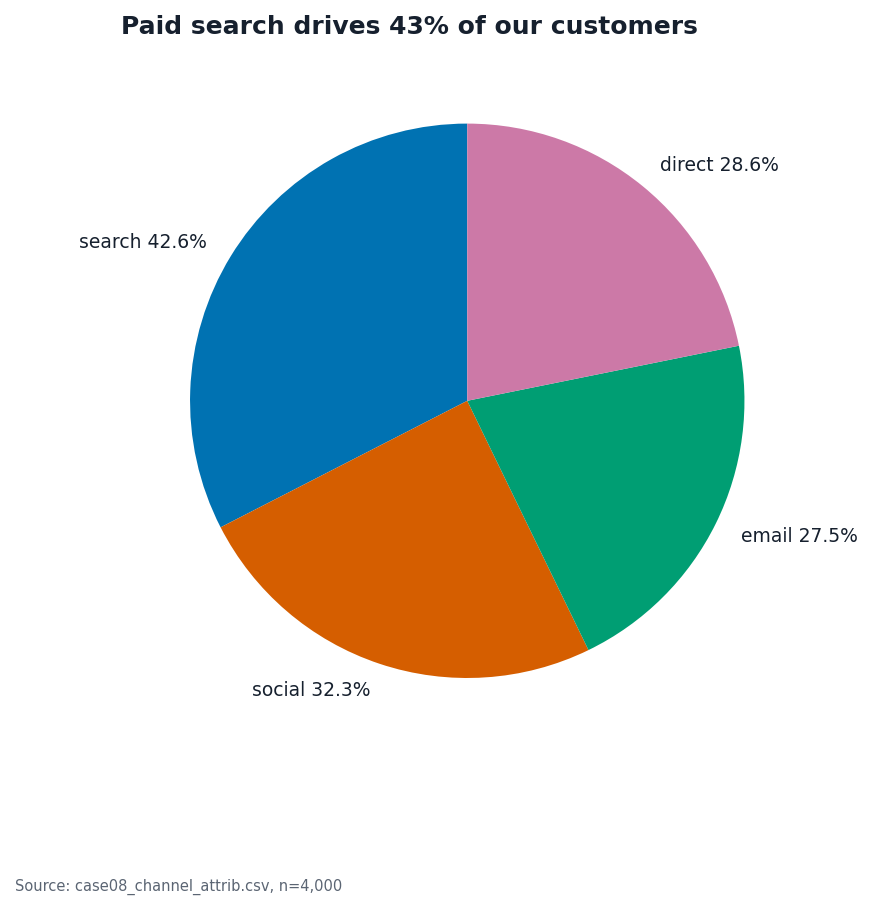

In [16]:
df = pd.read_csv(DATA / "case08_channel_attrib.csv")
cols = [c for c in df.columns if c.startswith("touch_")]
pct = df[cols].sum() / len(df) * 100
check("42.6 / 32.3 / 27.5 / 28.6", [round(v, 1) for v in pct] == [42.6, 32.3, 27.5, 28.6])
print("sum of the four 'shares':", round(pct.sum(), 1))

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(pct, labels=[f"{c[6:]} {v:.1f}%" for c, v in pct.items()],
       colors=PALETTE["series"] + [PALETTE["series_4th"]], startangle=90)
ax.set_title("Paid search drives 43% of our customers")
save(fig, "case08_rebuild.png", f"Source: case08_channel_attrib.csv, n={len(df):,}")
plt.show()

### Case 8: my analysis

- **Conclusion the chart invites (1 sentence):** Paid search drives 43% of our customers.
- **First objection I thought of, and the evidence it does not hold here:** That 4,000 customers is too few to trust 42.6%. The sampling error is only about ±1.5 points (1.96·√(0.426·0.574/4000)), so the number is solid; what is wrong is what it counts.
- **Mechanism (named precisely, with the number that shows it):** **The categories are not mutually exclusive.** The flags are *touches*, and 1,105 of 4,000 customers (**27.6%**) have two or more (980 two, 116 three, 9 four): 5,239 touches for 4,000 customers, so the four "shares" sum to **131.0%** and a pie (which must sum to 100%) is invalid. Only **25.9%** of customers (1,037) touched search and nothing else; "touched" is also not "drove".

*Hint to myself:* run `tslib.exclusivity_check` and read n_multi.

{'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}


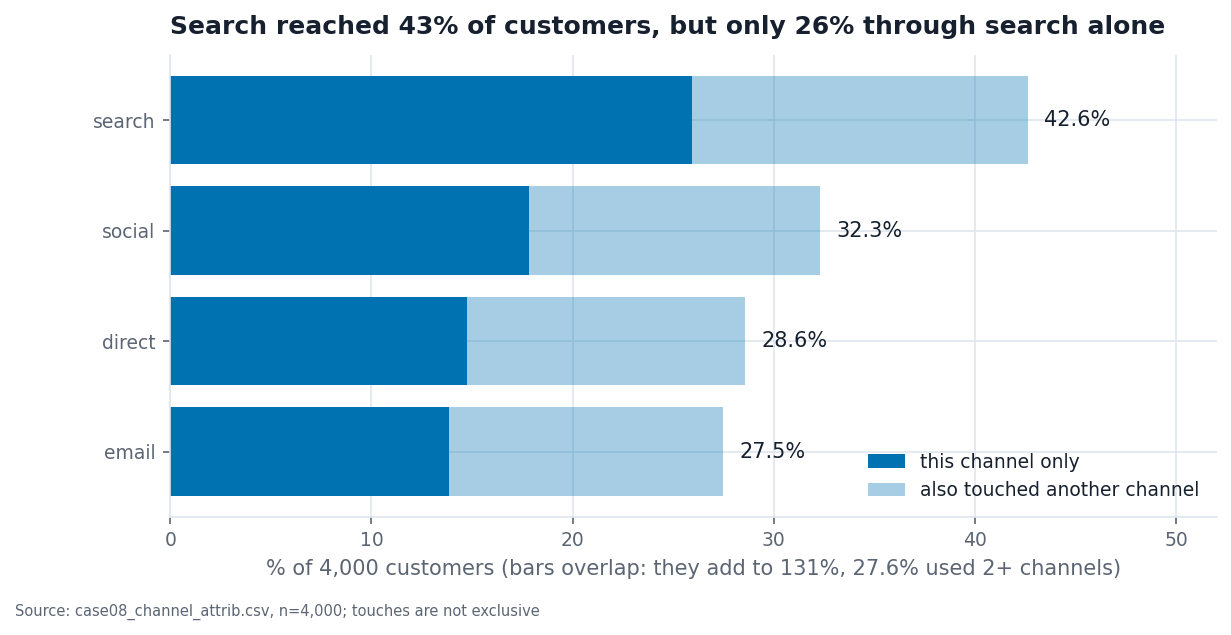

In [17]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# Redesign, case 8: overlapping reach, not a partition
df = pd.read_csv(DATA / "case08_channel_attrib.csv")
cols = [c for c in df.columns if c.startswith("touch_")]
ex = tslib.exclusivity_check(df, cols)
print(ex)
k = df[cols].sum(axis=1)
only = pd.Series({c: ((df[c]) & (k == 1)).mean() * 100 for c in cols})
reach = df[cols].mean() * 100
order = reach.sort_values().index

fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(order))
ax.barh(y, only[order], color=C0, label="this channel only")
ax.barh(y, reach[order] - only[order], left=only[order], color=C0, alpha=0.35, label="also touched another channel")
for yi, c in zip(y, order):
    ax.text(reach[c] + 0.8, yi, f"{reach[c]:.1f}%", va="center")
ax.set_yticks(y); ax.set_yticklabels([c[6:] for c in order])
ax.set_xlim(0, 52)
ax.set_title("Search reached 43% of customers, but only 26% through search alone")
ax.set_xlabel("% of 4,000 customers (bars overlap: they add to 131%, 27.6% used 2+ channels)")
ax.legend(loc="lower right")
save(fig, "case08_redesign.png", "Source: case08_channel_attrib.csv, n=4,000; touches are not exclusive")
plt.show()

---
## Case 9: "Premium is now 38% of revenue, a record"

**Recipe:** premium / total per quarter, line from zero, annotate the last point.

[PASS] 24.0% -> 38.0% 


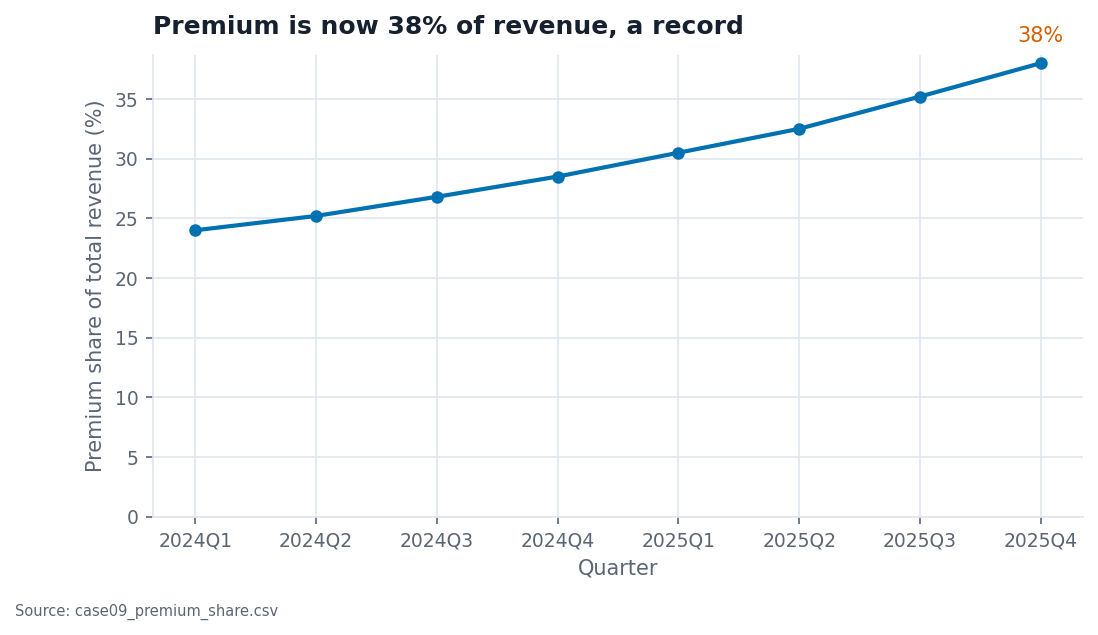

In [18]:
df = pd.read_csv(DATA / "case09_premium_share.csv")
sh = df.premium_revenue_pkr_m / df.total_revenue_pkr_m * 100
check("24.0% -> 38.0%", round(sh.iloc[0], 1) == 24.0 and round(sh.iloc[-1], 1) == 38.0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df.quarter, sh, marker="o", color=C0)
ax.set_ylim(0)
ax.annotate(f"{sh.iloc[-1]:.0f}%", (df.quarter.iloc[-1], sh.iloc[-1]), xytext=(0, 10),
            textcoords="offset points", ha="center", color=C1)
ax.set_title("Premium is now 38% of revenue, a record")
ax.set_xlabel("Quarter")
ax.set_ylabel("Premium share of total revenue (%)")
save(fig, "case09_rebuild.png", "Source: case09_premium_share.csv")
plt.show()

### Case 9: my analysis

- **Conclusion the chart invites (1 sentence):** Premium is booming: its share of revenue is a record 38%.
- **First objection I thought of, and the evidence it does not hold here:** That premium revenue is growing and the share is just the proof. It is not: premium revenue is 240.0 in 2024Q1 and 228.0 in 2025Q4 (−5.0%) and has been flat at 227–229 since 2025Q1.
- **Mechanism (named precisely, with the number that shows it):** **A shrinking denominator.** Total revenue fell from 1,000 to 600 (−40%) and non-premium from 760 to 372 (−51%). The share rises 24.0% → 38.0% because the rest of the business collapsed, not because premium grew. A share chart cannot show which of numerator and denominator moved.

*Hint to myself:* what happened to premium revenue itself, and to the total? Plot both.

premium 240 -> 228 (-5.0%); total 1000 -> 600 (-40.0%)
non-premium 760 -> 372 (-51.1%)


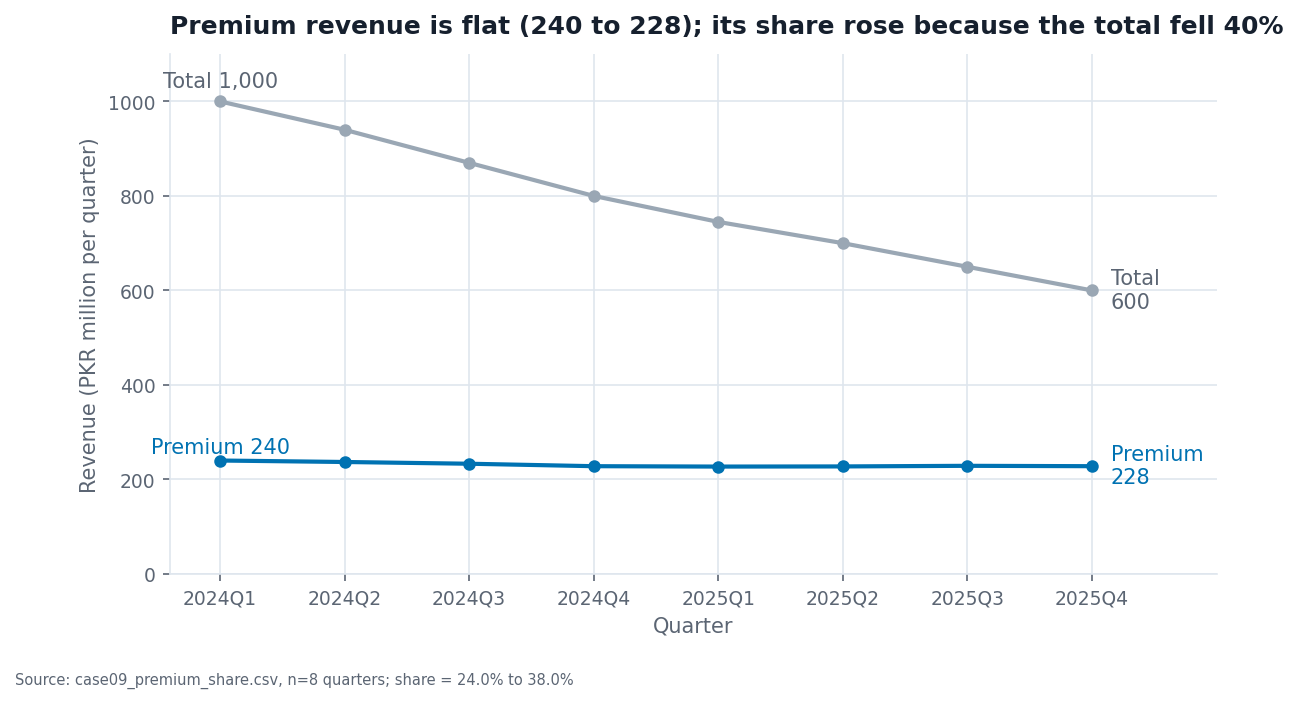

In [19]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
# Redesign, case 9: numerator and denominator, same units, no dual axis
df = pd.read_csv(DATA / "case09_premium_share.csv")
print(f"premium {df.premium_revenue_pkr_m.iloc[0]:.0f} -> {df.premium_revenue_pkr_m.iloc[-1]:.0f} "
      f"({df.premium_revenue_pkr_m.iloc[-1] / df.premium_revenue_pkr_m.iloc[0] - 1:+.1%}); "
      f"total {df.total_revenue_pkr_m.iloc[0]:.0f} -> {df.total_revenue_pkr_m.iloc[-1]:.0f} "
      f"({df.total_revenue_pkr_m.iloc[-1] / df.total_revenue_pkr_m.iloc[0] - 1:+.1%})")
nonp = df.total_revenue_pkr_m - df.premium_revenue_pkr_m
print(f"non-premium {nonp.iloc[0]:.0f} -> {nonp.iloc[-1]:.0f} ({nonp.iloc[-1] / nonp.iloc[0] - 1:+.1%})")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df.quarter, df.total_revenue_pkr_m, marker="o", color=GREY)
ax.plot(df.quarter, df.premium_revenue_pkr_m, marker="o", color=C0)
ax.text(7.15, df.total_revenue_pkr_m.iloc[-1], "Total\n600", color=PALETTE["ink_soft"], va="center")
ax.text(7.15, df.premium_revenue_pkr_m.iloc[-1], "Premium\n228", color=C0, va="center")
ax.text(0, 255, "Premium 240", color=C0, ha="center")
ax.text(0, 1030, "Total 1,000", color=PALETTE["ink_soft"], ha="center")
ax.set_ylim(0, 1100); ax.set_xlim(-0.4, 8)
ax.set_title("Premium revenue is flat (240 to 228); its share rose because the total fell 40%")
ax.set_xlabel("Quarter")
ax.set_ylabel("Revenue (PKR million per quarter)")
save(fig, "case09_redesign.png", "Source: case09_premium_share.csv, n=8 quarters; share = 24.0% to 38.0%")
plt.show()